# 08 · Does the model work on real fleet data?

**Question.** Studies 01–07 use a made-up depot. Here the trucks come from **real operating schedules** of a heavy-duty delivery fleet, and we check whether the charging model and the XY + Dicke QAOA still work, on many real nights rather than one hand-picked night.

**Data.** `data/nlr_fleet_2021/`: real-world schedules of three delivery fleets from NREL's Fleet DNA program, published with Borlaug et al. (2021), *Nature Energy* 6, 673–682 (BSD-3 license; see `SOURCE.md`). One record is one truck on one day: when it left the depot, when it came back, and the miles it drove. Charging needed = miles × 1.8 kWh/mile at 100 kW, rounded up to whole hours. Both numbers are the NLR study's own assumptions.

**Prices are placeholders.** We do not have real hourly prices yet, so every night uses the depot's made-up tariff (32, 14, 9, 21 ¢/kWh for 10 pm–2 am). The trucks are real; the dollar amounts are not. Real prices only need to replace `TARIFF` below.

In [ ]:
%pip install -q numpy scipy matplotlib qiskit==2.3.1 qiskit-aer==0.17.2 qiskit-ibm-runtime==0.50.0

In [1]:
# Google Colab: download the project code (evqaoa/, experiments/, results/) if it is not here yet.
import os, sys
if 'google.colab' in sys.modules and not (os.path.isdir('evqaoa') or os.path.isdir('../evqaoa')):
    !git clone -q https://github.com/SakxamShrestha/quant5-fisk-IQ-hackathon
    %cd quant5-fisk-IQ-hackathon/notebooks

In [2]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT))

In [3]:
import json, platform, time
import numpy as np
import matplotlib.pyplot as plt
import qiskit, scipy
from evqaoa.real_data import (FLEETS, PLACEHOLDER_TARIFF, WINDOW, eligible, load_truck_days,
                              make_night, sample_nights)
from experiments import real_nights as rn

OUT = ROOT / 'results' / '08_real_fleet'; OUT.mkdir(parents=True, exist_ok=True)
SEED = 0
TARIFF = PLACEHOLDER_TARIFF      # replace with real prices: one per hour, 10 pm to 2 am (cents/kWh)
# categorical slots 1-3 of the validated palette, gray for the simple rules and reference lines
COLORS = {'qaoa_p1': '#2a78d6', 'qaoa_p2': '#eb6834', 'best': '#1baf7a', 'rule': '#9aa5b1'}
VERSIONS = dict(python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__,
                qiskit=qiskit.__version__)
print(f'fleet {rn.FLEET} | {rn.N_NIGHTS} nights of 3 trucks | {WINDOW[0]}:00 to {WINDOW[1]}:00 | '
      f'prices {TARIFF}{" (placeholder)" if TARIFF == PLACEHOLDER_TARIFF else ""}')
print(VERSIONS)

fleet fleet2-warehouse-delivery | 50 nights of 3 trucks | 22:00 to 2:00 | prices (32, 14, 9, 21) (placeholder)
{'python': '3.13.3', 'numpy': '2.1.3', 'scipy': '1.15.3', 'qiskit': '2.3.1'}


## 1. Which fleet?

A truck-day can be used only if the truck is parked for the whole 10 pm–2 am window and needs between 1 and 4 hours of charging (the window has 4 one-hour slots).

In [4]:
print(f"{'fleet':27s} {'truck-days':>10} {'usable':>12}   hours of charging needed (usable truck-days)")
for f in FLEETS:
    s = rn.fleet_summary(f)
    print(f"{s['fleet']:27s} {s['truck_days']:10d} {s['eligible']:5d} ({s['eligible'] / s['truck_days']:4.0%})   {s['hours_needed']}")

fleet                       truck-days       usable   hours of charging needed (usable truck-days)
fleet1-beverage-delivery            76    76 (100%)   {1: 10, 2: 61, 3: 5}
fleet2-warehouse-delivery          100    98 ( 98%)   {1: 36, 2: 35, 3: 26, 4: 1}
fleet3-food-delivery               236   150 ( 64%)   {1: 60, 2: 40, 3: 30, 4: 20}


We use the **warehouse fleet**. Almost all of its truck-days fit the window, and their charging needs are a real mix of 1, 2 and 3 hours. The beverage fleet fits too, but 80% of its trucks need exactly 2 hours, so nearly every night would be the same problem. The food fleet loses a third of its truck-days (many leave before 2 am or need more than 4 hours), so its usable nights would be biased toward short routes.

## 2. One real night

Each night is 3 truck-days drawn at random (fixed seed) from the usable warehouse truck-days, giving the same 12-qubit problem size as the depot in studies 01–07. The records carry no truck ID or date, so the 3 trucks are real but were not necessarily parked together on the same night. As in the NLR code, a truck's next morning repeats its own schedule.

In [5]:
nights = sample_nights(eligible(load_truck_days(rn.FLEET)), rn.N_NIGHTS, seed=SEED)

def clock(hours):
    minutes = int(round(hours * 60))
    return f'{minutes // 60:02d}:{minutes % 60:02d}'

for d in nights[0]:
    print(f'truck-day {d.day_id:3d}: left {clock(d.leaves_at)}, back {clock(d.returns_at)}, {d.miles:5.1f} miles '
          f'-> {d.kwh_needed:5.1f} kWh -> {d.hours_needed()} h at 100 kW')
problem = make_night(nights[0], TARIFF)
print(problem, f'| {problem.n_qubits} qubits')

truck-day  64: left 07:37, back 16:14, 194.4 miles -> 349.9 kWh -> 4 h at 100 kW
truck-day  53: left 09:01, back 16:45,  73.3 miles -> 131.9 kWh -> 2 h at 100 kW
truck-day  84: left 07:51, back 16:31,  27.1 miles ->  48.9 kWh -> 1 h at 100 kW
ChargingProblem(n_vehicles=3, n_slots=4, tariff=(32, 14, 9, 21), demand=(4, 2, 1)) | 12 qubits


## 3. QAOA on 50 real nights

For every night we build the same three-goal model as studies 01–07 (weights 0.5 / 0.3 / 0.2 for bill / peak / battery wear) and optimise XY + Dicke QAOA at p = 1 and p = 2 on the exact valid-plan simulator of study 03. It gives the same energies as the Qiskit circuit (checked in `tests/test_real_nights.py`) and is much faster.

Two changes from studies 01–07, both from the code review:
- **γ is searched over its real range.** Start angles draw γ from [0, 2π / spread], where spread is the energy range of the valid plans, instead of [0, π]. The optimiser also works on rescaled angles so that β and γ change on similar scales.
- **p = 2 starts from a stretched copy of the p = 1 angles** (INTERP, Zhou et al. 2020) plus 4 random starts, instead of appending a zero layer.

Scores: **P(optimal)** is the chance one shot returns a best plan, compared with picking a random valid plan; the **approximation ratio** is the average plan quality (1 = always optimal).

In [6]:
t0 = time.time()
rows = rn.run_nights(rn.FLEET, rn.N_NIGHTS, TARIFF, seed=SEED)
summary = rn.summarise(rows)
runtime = time.time() - t0
json.dump(dict(fleet=rn.FLEET, window=list(WINDOW), tariff=list(TARIFF),
               tariff_is_placeholder=TARIFF == PLACEHOLDER_TARIFF, weights=list(rn.WEIGHTS), seed=SEED,
               restarts=rn.RESTARTS, maxiter=rn.MAXITER, runtime_s=runtime, versions=VERSIONS,
               summary=summary, nights=rows),
          open(OUT / 'real_nights.json', 'w'), indent=1)
print(f"{len(rows)} nights in {runtime:.0f} s; {summary['distinct_problems']} distinct problems "
      f"(with one price list, nights differ only in their charging-hour mix)")
print('charging-hour mixes:', summary['demand_mix'])
for p in rn.REPS:
    s = summary[f'p{p}']
    print(f"p = {p}: median P(optimal) {s['p_optimal_median']:.3f} = {s['gain_median']:.2f}x a random valid plan "
          f"(range {s['gain_min']:.2f}-{s['gain_max']:.2f}x) | beats random on {s['nights_beating_random']}/{len(rows)} nights "
          f"| most likely plan is optimal on {s['nights_most_likely_optimal']} | median approx. ratio "
          f"{s['approx_ratio_median']:.3f} | optimiser converged on {s['nights_converged']}/{len(rows)}")

50 nights in 31 s; 10 distinct problems (with one price list, nights differ only in their charging-hour mix)
charging-hour mixes: {'1-1-1': 4, '1-1-2': 6, '1-1-3': 6, '1-2-2': 5, '1-2-3': 12, '1-2-4': 3, '1-3-3': 2, '2-2-2': 2, '2-2-3': 5, '2-3-3': 5}
p = 1: median P(optimal) 0.074 = 2.44x a random valid plan (range 1.75-3.54x) | beats random on 50/50 nights | most likely plan is optimal on 19 | median approx. ratio 0.777 | optimiser converged on 50/50
p = 2: median P(optimal) 0.100 = 2.63x a random valid plan (range 0.68-8.00x) | beats random on 46/50 nights | most likely plan is optimal on 5 | median approx. ratio 0.818 | optimiser converged on 48/50


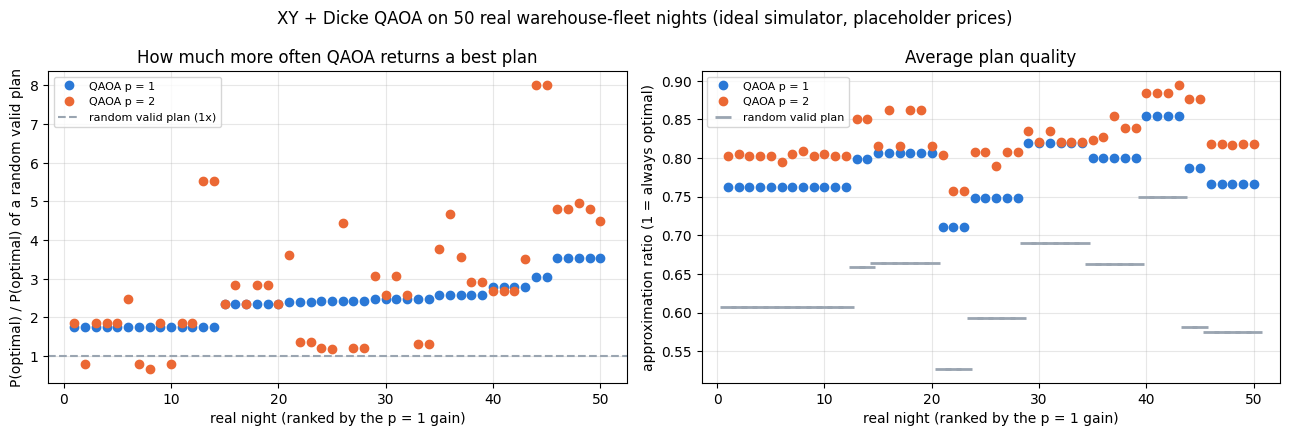

In [7]:
order = np.argsort([r['p1']['gain_vs_random'] for r in rows])
rank = np.arange(1, len(rows) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for p in rn.REPS:
    color, label = COLORS[f'qaoa_p{p}'], f'QAOA p = {p}'
    axes[0].plot(rank, [rows[i][f'p{p}']['gain_vs_random'] for i in order], 'o', ms=6, color=color, label=label)
    axes[1].plot(rank, [rows[i][f'p{p}']['approx_ratio'] for i in order], 'o', ms=6, color=color, label=label)
axes[0].axhline(1, ls='--', color=COLORS['rule'], label='random valid plan (1x)')
axes[1].plot(rank, [rows[i]['ar_random'] for i in order], '_', ms=12, mew=2, color=COLORS['rule'],
             label='random valid plan')
axes[0].set_ylabel('P(optimal) / P(optimal) of a random valid plan')
axes[0].set_title('How much more often QAOA returns a best plan')
axes[1].set_ylabel('approximation ratio (1 = always optimal)')
axes[1].set_title('Average plan quality')
for ax in axes:
    ax.set_xlabel('real night (ranked by the p = 1 gain)')
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle(f'XY + Dicke QAOA on {len(rows)} real warehouse-fleet nights (ideal simulator, placeholder prices)')
plt.tight_layout(); plt.savefig(OUT / 'quality_per_night.png', dpi=150); plt.show()

## 4. In real units, against what depots do today

Each night's plan is turned into dollars, the depot's highest load and battery wear, then averaged over all nights. Lower is better for all three.
- **Charge right away**: every truck starts at 10 pm (the NLR study's "immediate" strategy).
- **Charge as late as possible**: every truck finishes at 2 am (NLR's "delayed").
- **QAOA**: the average over its shots, not its single best shot. With only 24–216 valid plans per night, enough random guesses would also hit the best one.
- **Best plan**: the brute-force optimum of the same three-goal score.

Each charging hour draws the full 100 kW, so an hour costs its price (¢/kWh) in dollars.

plan                         $ / night  peak kW starts+stops
charge right away (10 pm)        130.2      300         2.94
charge as late as possible        92.7      300         2.94
QAOA p = 1                        99.1      224         4.66
QAOA p = 2                        95.6      232         4.35
best plan (brute force)           95.2      202         3.62


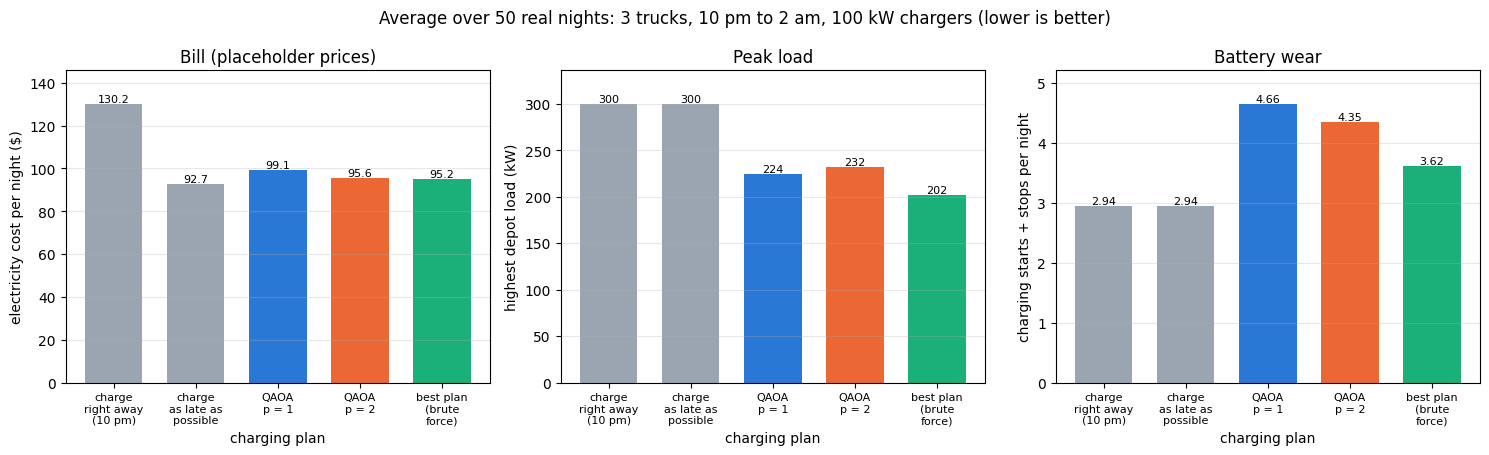

In [8]:
LABELS = {'immediate': 'charge\nright away\n(10 pm)', 'delayed': 'charge\nas late as\npossible',
          'qaoa_p1': 'QAOA\np = 1', 'qaoa_p2': 'QAOA\np = 2', 'best': 'best plan\n(brute\nforce)'}
BAR_COLORS = [COLORS['rule'], COLORS['rule'], COLORS['qaoa_p1'], COLORS['qaoa_p2'], COLORS['best']]
units = summary['units']
print(f"{'plan':28s} {'$ / night':>9} {'peak kW':>8} {'starts+stops':>12}")
for src, label in LABELS.items():
    u = units[src]
    print(f"{label.replace(chr(10), ' '):28s} {u['dollars']:9.1f} {u['peak_kw']:8.0f} {u['start_stops']:12.2f}")

specs = (('dollars', 'electricity cost per night ($)', 'Bill (placeholder prices)', '%.1f'),
         ('peak_kw', 'highest depot load (kW)', 'Peak load', '%.0f'),
         ('start_stops', 'charging starts + stops per night', 'Battery wear', '%.2f'))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (key, ylabel, title, fmt) in zip(axes, specs):
    bars = ax.bar(range(len(LABELS)), [units[s][key] for s in LABELS], 0.7, color=BAR_COLORS)
    ax.bar_label(bars, fmt=fmt, fontsize=8)
    ax.margins(y=0.12)
    ax.set_xticks(range(len(LABELS))); ax.set_xticklabels(LABELS.values(), fontsize=8)
    ax.set_xlabel('charging plan'); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.grid(axis='y', alpha=0.3)
fig.suptitle(f'Average over {len(rows)} real nights: 3 trucks, 10 pm to 2 am, 100 kW chargers (lower is better)')
plt.tight_layout(); plt.savefig(OUT / 'real_units.png', dpi=150); plt.show()

## 5. Ready for the real chip

We pick a **typical** night (the median p = 2 gain, not the best one), compile its p = 1 and p = 2 circuits exactly as in studies 05–07, and predict the result with the FakeFez noisy simulator. This costs no QPU time.

In [9]:
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeFez
from evqaoa import charging_model, exact_baselines
from experiments.noise import circuit_stats, sample, score

pick = rn.typical_night(rows)
row = rows[pick]
night = rn.night_problem(row)
model = charging_model(night, rn.WEIGHTS)
base = exact_baselines(night, model)
print(f"night {pick}: truck-days {[t['day_id'] for t in row['trucks']]}, charging hours {row['demand']}, "
      f"{row['n_valid']} valid plans, random valid plan finds the best one {row['p_opt_random']:.3f} of the time")
backend = FakeFez()
compiled = rn.compile_night(row, backend)
noisy = AerSimulator.from_backend(backend)
prediction = {}
for p in rn.REPS:
    name = rn.run_name(p)
    s = score(sample(compiled[name], noisy, 4096), model, base, night)
    prediction[name] = dict(circuit_stats(compiled[name]), ideal_p_optimal=row[f'p{p}']['p_optimal'], fakefez=s)
    print(f"{name}: {prediction[name]['two_qubit_gates']} two-qubit gates | ideal P(optimal) {row[f'p{p}']['p_optimal']:.3f} "
          f"| FakeFez: {s['valid_rate']:.0%} valid, P(optimal) {s['p_optimal']:.3f}, "
          f"P(optimal | valid) {s['p_optimal_valid']:.3f}")
json.dump(dict(night=pick, truck_day_ids=[t['day_id'] for t in row['trucks']], demand=row['demand'],
               tariff=row['tariff'], p_opt_random=row['p_opt_random'], shots=4096, prediction=prediction,
               versions=VERSIONS),
          open(OUT / 'fakefez_prediction.json', 'w'), indent=2)

night 12: truck-days [83, 71, 69], charging hours [1, 1, 1], 64 valid plans, random valid plan finds the best one 0.094 of the time


real_night_p1: 209 two-qubit gates | ideal P(optimal) 0.261 | FakeFez: 51% valid, P(optimal) 0.108, P(optimal | valid) 0.211


real_night_p2: 357 two-qubit gates | ideal P(optimal) 0.252 | FakeFez: 34% valid, P(optimal) 0.070, P(optimal | valid) 0.204


### Running it on the real chip

`RUN_ON_IBM = True` sends one SamplerV2 job with the two circuits plus two readout-calibration circuits, in the same format as study 06 (about 8 s of QPU time on `ibm_fez`). It reads the IBM account saved in `~/.qiskit/`, never a token in the notebook (see notebook 06 for how to save one).

**Wait for the real prices before running it.** The prices change the problem, so a run now would have to be repeated.

In [10]:
RUN_ON_IBM = False        # True = submit to the real chip (uses QPU time)
BACKEND_NAME = 'ibm_fez'
HW_DIR = OUT / 'hardware'
if RUN_ON_IBM:
    from qiskit_ibm_runtime import QiskitRuntimeService
    from experiments.hardware import collect
    hw_backend = QiskitRuntimeService().backend(BACKEND_NAME)   # account from ~/.qiskit, never a token here
    job = rn.submit_night(row, hw_backend, HW_DIR)
    print(f'submitted job {job.job_id()} to {hw_backend.name}; waiting for it to finish ...')
    job.result()                                                  # blocks until the job is done
    collect(out_dir=HW_DIR)
if (HW_DIR / 'hw_counts.json').exists():
    from experiments.hardware_analysis import device_scores
    hw_counts = json.loads((HW_DIR / 'hw_counts.json').read_text())
    for p in rn.REPS:
        for variant, s in device_scores(hw_counts, rn.run_name(p), model, base, night).items():
            print(f"{rn.run_name(p)} {variant:18s}: {s['valid_rate']:.0%} valid, P(optimal | valid) {s['p_optimal_valid']:.3f}")
else:
    print('No hardware run yet (RUN_ON_IBM = False).')

No hardware run yet (RUN_ON_IBM = False).


## Findings & limitations

All results come from the ideal (noise-free) simulator unless stated otherwise. **All dollar figures use placeholder prices.**

**What we found**

1. **The model runs unchanged on real trucks.** 98 of the 100 warehouse truck-days fit the 10 pm–2 am window, and every night becomes the same kind of 12-qubit problem as the made-up depot. The circuits did not change.
2. **QAOA beats a random valid plan on every real night at p = 1.** It returns a best plan a median **2.44×** as often as a random valid plan (range 1.75–3.54× over the 50 nights). At p = 2 the median rises to **2.63×** (median P(optimal) 0.100) and the median approximation ratio from 0.777 to 0.818.
3. **A better average score does not always mean more optimal plans.** On 4 nights (all the same 1 + 2 + 3-hour problem), p = 2 improves the average score but returns the exact best plan less often than a random guess (0.68–0.80×). On that problem the second-best plan is within 2% of the best score, and QAOA spreads its weight over near-best plans. QAOA minimises the average score; it is not built to maximise P(optimal).
4. **In real units, QAOA's plans sit close to the brute-force best.** Averaged over the 50 nights, QAOA p = 2 costs $95.6 a night, against $95.2 for the plan with the best three-goal score and $130.2 for charging every truck at 10 pm. It keeps the depot's highest load at 232 kW against 300 kW for both simple rules. It pays for this with more charging starts and stops (4.4, against 2.9 for the rules and 3.6 for the best plan). Charging as late as possible is the cheapest ($92.7) but keeps the 300 kW peak; the three-goal score gives up a little money for a lower peak.
5. **The hardware prediction matches studies 05–06.** For a typical night (median gain; three trucks needing 1 hour each), FakeFez predicts 51% valid shots at p = 1 and 34% at p = 2. With invalid shots discarded, the best plan comes out 21% and 20% of the time, against 9.4% for a random valid plan. Study 06 found the real chip keeps about half the valid share that FakeFez predicts.

**Limitations**

- **Placeholder prices.** With one price list, the 50 nights are only 10 distinct problems (they differ only in charging hours). Real hourly prices for each night will make every night different and give real dollar figures.
- **Truck-days, not real nights.** The data has no truck ID or date, so the 3 trucks in a night were not necessarily at the depot together.
- **Simplified charging.** Energy is rounded up to whole hours, every charging hour draws the full 100 kW, and 1.8 kWh/mile and 100 kW are the NLR study's assumptions, not measurements.
- **Short window.** Real trucks are parked from about 5 pm to 8 am; we schedule only 10 pm–2 am. A longer window needs more qubits, or support for arrival and departure times.
- **Made-up weights.** The 0.5 / 0.3 / 0.2 weights on bill, peak and battery wear are still our choice.
- **No chip run yet.** Section 5 is a FakeFez prediction. Run it on `ibm_fez` once real prices are in.